# 1. Dataset Selection, EDA and Data Preprocessing

## 1.1 Dataset Description

The Phishing Websites Dataset is obtained from the UCI
Machine Learning Repository.

It contains 11,055 instances and 30 input features
representing characteristics of phishing and
legitimate websites.

The objective is to develop machine learning models
to identify phishing websites.

Dataset Source:
https://archive.ics.uci.edu/dataset/327/phishing

Target Labels:
- 0: Phishing Website
- 1: Legitimate Website

### 1.2 Import Libraries and Load Dataset

Pandas and NumPy are used for data manipulation.
Matplotlib is used for visualization.

The ucimlrepo package downloads the dataset directly
from the UCI Machine Learning Repository.

In [46]:
# Install the required package
!pip install -q ucimlrepo

In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

# Configure pandas display
pd.set_option("display.max_columns", None)

# Download UCI Phishing Websites Dataset
phishing_data = fetch_ucirepo(id=327)

# Extract input features and original target
X_raw = phishing_data.data.features.copy()
y_raw = phishing_data.data.targets.copy()

# Display initial records
display(X_raw.head())

print("Dataset downloaded successfully!")

,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,port,https_token,request_url,url_of_anchor,links_in_tags,sfh,submitting_to_email,abnormal_url,redirect,on_mouseover,rightclick,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,1,-1,1,-1,1,-1,-1,-1,0,1,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1,0,-1,1,1,1


Dataset downloaded successfully!


### 1.3 Dataset Inspection and Target Transformation

The dataset dimensions, feature names, data types,
and target distribution are examined.

The original target labels are transformed into
binary encoding:

- 1: Phishing Website
- 0: Legitimate Website

This makes phishing detection the positive class
for subsequent model evaluation.

In [3]:
# Extract original target column
original_target = pd.to_numeric(
    y_raw.iloc[:, 0],
    errors="raise"
)

# Verify original labels
assert set(original_target.unique()) == {-1, 1}

# Transform target labels
y = (original_target == -1).astype(int)

# Assign target column name
y.name = "is_phishing"

# Prepare input features
X = X_raw.copy()

# Combine features and transformed target
df = X.copy()
df["is_phishing"] = y

# Display dataset information
print("Dataset Shape:", df.shape)
print("Total Instances:", X.shape[0])
print("Total Input Features:", X.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe().T)

print("\nTarget Distribution:")
display(y.value_counts().sort_index())

Dataset Shape: (11055, 31)
Total Instances: 11055
Total Input Features: 30

Column Names:
['having_ip_address', 'url_length', 'shortining_service', 'having_at_symbol', 'double_slash_redirecting', 'prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'favicon', 'port', 'https_token', 'request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'submitting_to_email', 'abnormal_url', 'redirect', 'on_mouseover', 'rightclick', 'popupwindow', 'iframe', 'age_of_domain', 'dnsrecord', 'web_traffic', 'page_rank', 'google_index', 'links_pointing_to_page', 'statistical_report', 'is_phishing']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 31 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   having_ip_address           11055 non-null  int64
 1   url_length                  11055 non-null  int64
 2   shortining_service          1

,count,mean,std,min,25%,50%,75%,max
having_ip_address,11055.0,0.313795,0.949534,-1.0,-1.0,1.0,1.0,1.0
url_length,11055.0,-0.633198,0.766095,-1.0,-1.0,-1.0,-1.0,1.0
shortining_service,11055.0,0.738761,0.673998,-1.0,1.0,1.0,1.0,1.0
having_at_symbol,11055.0,0.700588,0.713598,-1.0,1.0,1.0,1.0,1.0
double_slash_redirecting,11055.0,0.741474,0.671011,-1.0,1.0,1.0,1.0,1.0
prefix_suffix,11055.0,-0.734962,0.678139,-1.0,-1.0,-1.0,-1.0,1.0
having_sub_domain,11055.0,0.063953,0.817518,-1.0,-1.0,0.0,1.0,1.0
sslfinal_state,11055.0,0.250927,0.911892,-1.0,-1.0,1.0,1.0,1.0
domain_registration_length,11055.0,-0.336771,0.941629,-1.0,-1.0,-1.0,1.0,1.0
favicon,11055.0,0.628584,0.777777,-1.0,1.0,1.0,1.0,1.0



Target Distribution:


,count
is_phishing,
0,6157
1,4898


### 1.4 Data Quality Analysis

Missing values, duplicate records, and data types
are examined to assess dataset quality.

Duplicate feature vectors are identified because
they can cause data leakage during model evaluation.

Missing values, if present, will be handled through
training-only preprocessing pipelines.

In [4]:
# Check missing values
print("Total Missing Values:", df.isnull().sum().sum())

# Display columns containing missing values
display(
    df.isnull().sum()[df.isnull().sum() > 0]
)

# Count duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Count duplicate feature vectors
print("Duplicate Feature Vectors:", X.duplicated().sum())

# Count unique feature vectors
print(
    "Unique Feature Vectors:",
    X.drop_duplicates().shape[0]
)

# Check feature data types
print("\nFeature Data Types:")
print(X.dtypes.value_counts())

# Check non-numeric columns
print(
    "\nNon-numeric Features:",
    X.select_dtypes(exclude=np.number).columns.tolist()
)

Total Missing Values: 0


,0



Duplicate Records: 5206
Duplicate Feature Vectors: 5270
Unique Feature Vectors: 5785

Feature Data Types:
int64    30
Name: count, dtype: int64

Non-numeric Features: []


### 1.5 Exploratory Data Analysis

Exploratory Data Analysis is performed to understand
the distribution and characteristics of the dataset.

The analysis includes target class distribution,
feature value distribution, and relationships
between input features and the target variable.

Class Distribution:
is_phishing
0    6157
1    4898
Name: count, dtype: int64

Class Distribution Percentage:
is_phishing
0    55.69
1    44.31
Name: proportion, dtype: float64


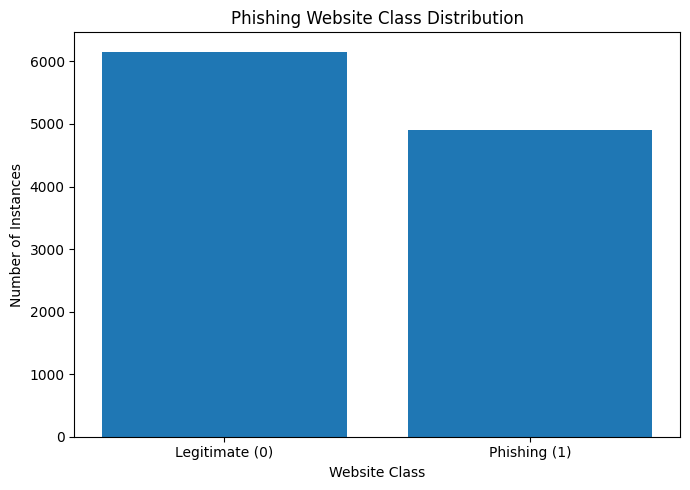

In [5]:
# Calculate class distribution
class_counts = y.value_counts().sort_index()

print("Class Distribution:")
print(class_counts)

print("\nClass Distribution Percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

# Visualize class distribution
plt.figure(figsize=(7, 5))

plt.bar(
    ["Legitimate (0)", "Phishing (1)"],
    [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ]
)

plt.title("Phishing Website Class Distribution")
plt.xlabel("Website Class")
plt.ylabel("Number of Instances")

plt.tight_layout()
plt.show()

In [6]:
# Generate feature summary
feature_summary = pd.DataFrame({
    "Data Type": X.dtypes,
    "Unique Values": X.nunique(),
    "Minimum": X.min(),
    "Maximum": X.max()
})

display(feature_summary)

# Examine observed values
for column in X.columns:
    print(f"{column}: {sorted(X[column].dropna().unique())}")

,Data Type,Unique Values,Minimum,Maximum
having_ip_address,int64,2,-1,1
url_length,int64,3,-1,1
shortining_service,int64,2,-1,1
having_at_symbol,int64,2,-1,1
double_slash_redirecting,int64,2,-1,1
prefix_suffix,int64,2,-1,1
having_sub_domain,int64,3,-1,1
sslfinal_state,int64,3,-1,1
domain_registration_length,int64,2,-1,1
favicon,int64,2,-1,1


having_ip_address: [np.int64(-1), np.int64(1)]
url_length: [np.int64(-1), np.int64(0), np.int64(1)]
shortining_service: [np.int64(-1), np.int64(1)]
having_at_symbol: [np.int64(-1), np.int64(1)]
double_slash_redirecting: [np.int64(-1), np.int64(1)]
prefix_suffix: [np.int64(-1), np.int64(1)]
having_sub_domain: [np.int64(-1), np.int64(0), np.int64(1)]
sslfinal_state: [np.int64(-1), np.int64(0), np.int64(1)]
domain_registration_length: [np.int64(-1), np.int64(1)]
favicon: [np.int64(-1), np.int64(1)]
port: [np.int64(-1), np.int64(1)]
https_token: [np.int64(-1), np.int64(1)]
request_url: [np.int64(-1), np.int64(1)]
url_of_anchor: [np.int64(-1), np.int64(0), np.int64(1)]
links_in_tags: [np.int64(-1), np.int64(0), np.int64(1)]
sfh: [np.int64(-1), np.int64(0), np.int64(1)]
submitting_to_email: [np.int64(-1), np.int64(1)]
abnormal_url: [np.int64(-1), np.int64(1)]
redirect: [np.int64(0), np.int64(1)]
on_mouseover: [np.int64(-1), np.int64(1)]
rightclick: [np.int64(-1), np.int64(1)]
popupwindow: [n

,Correlation
sslfinal_state,-0.714741
url_of_anchor,-0.692935
prefix_suffix,-0.348606
web_traffic,-0.346103
having_sub_domain,-0.298323
request_url,-0.253372
links_in_tags,-0.248229
domain_registration_length,0.225789
sfh,-0.221419
google_index,-0.128950


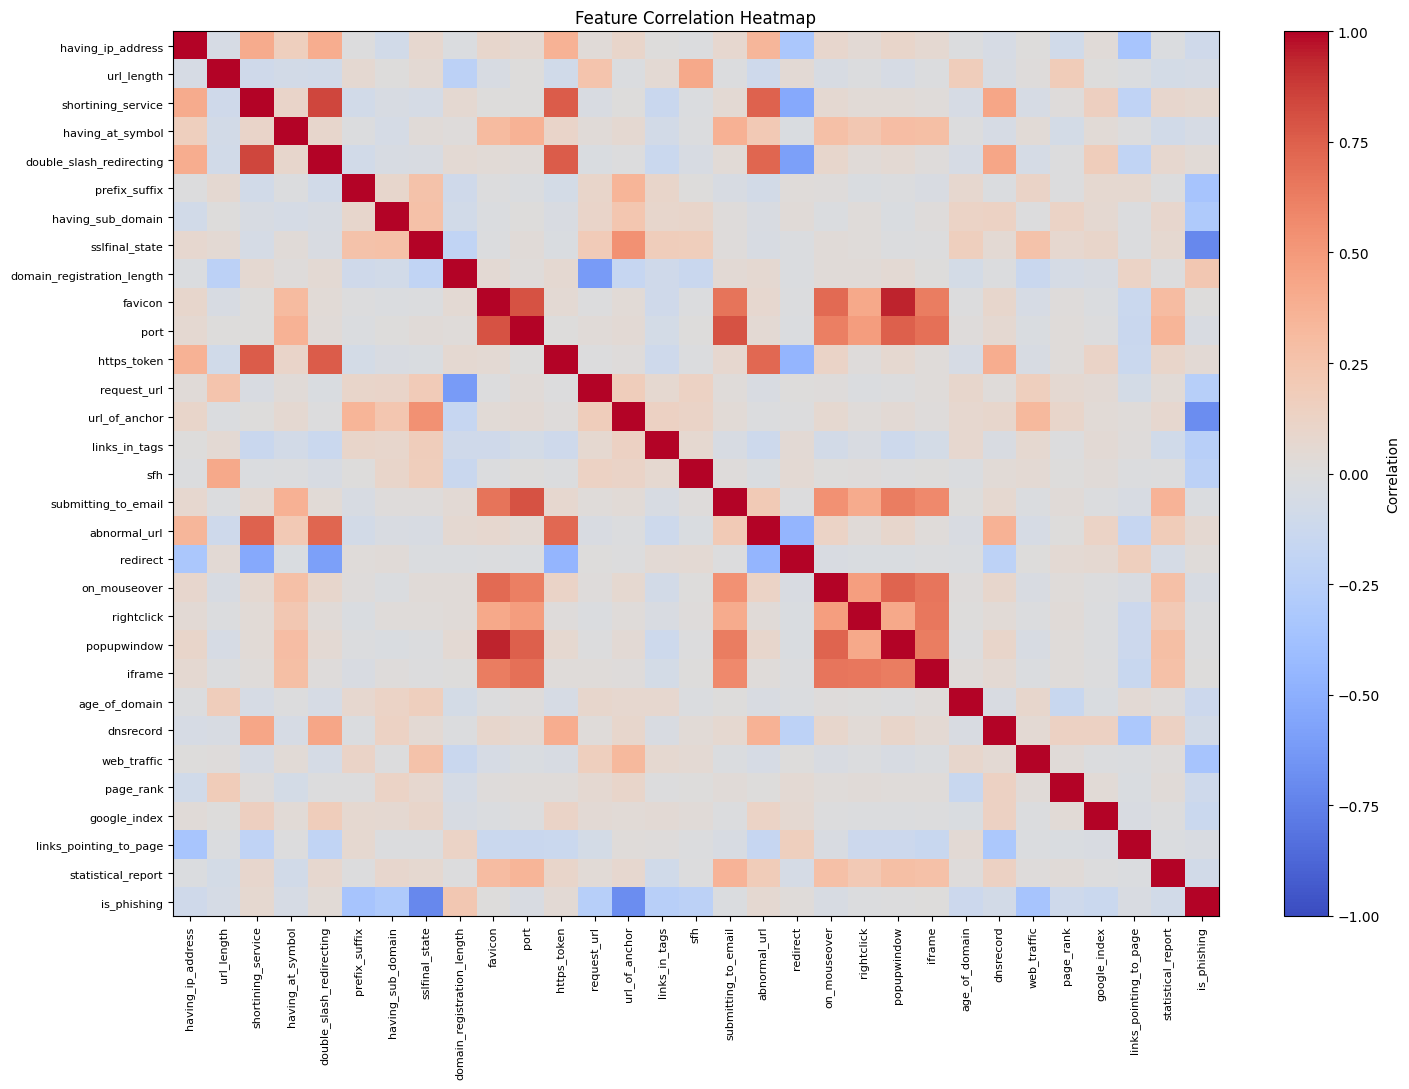

In [7]:
# Combine features and target for correlation analysis
correlation_data = pd.concat([X, y], axis=1)

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Display feature correlation with target
target_correlation = (
    correlation_matrix["is_phishing"]
    .drop("is_phishing")
    .sort_values(key=abs, ascending=False)
)

display(target_correlation.to_frame(name="Correlation"))

# Plot correlation heatmap
plt.figure(figsize=(15, 11))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90,
    fontsize=8
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    fontsize=8
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

### 1.6 Duplicate Feature Group Identification

Identical feature vectors are assigned unique group IDs.

These groups ensure that duplicate observations
remain within the same dataset partition.

This prevents identical feature vectors from appearing
simultaneously in training and testing data.

In [8]:
# Generate group IDs for identical feature vectors
groups, unique_groups = pd.factorize(
    pd.MultiIndex.from_frame(X),
    sort=False
)

# Calculate group statistics
group_data = pd.DataFrame({
    "group_id": groups,
    "target": y.values
})

group_sizes = group_data.groupby("group_id").size()

# Identify groups containing conflicting target labels
group_target_counts = (
    group_data.groupby("group_id")["target"].nunique()
)

conflicting_groups = (group_target_counts > 1).sum()

print("Total Records:", len(X))
print("Unique Feature Groups:", len(unique_groups))
print("Repeated Feature Groups:", (group_sizes > 1).sum())
print("Groups with Conflicting Labels:", conflicting_groups)

Total Records: 11055
Unique Feature Groups: 5785
Repeated Feature Groups: 2614
Groups with Conflicting Labels: 64


### 1.7 Training and Testing Dataset Split

The dataset is divided into training and testing
subsets using an approximately 80:20 ratio.

Stratified Group K-Fold is used to maintain class
proportions while keeping identical feature vectors
within the same partition.

A random state of 42 ensures reproducibility.

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

# Initialize grouped stratified cross-validation
group_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate approximately 80:20 split
train_indices, test_indices = next(
    group_splitter.split(
        X,
        y,
        groups=groups
    )
)

# Create training and testing features
X_train = X.iloc[train_indices].reset_index(drop=True)
X_test = X.iloc[test_indices].reset_index(drop=True)

# Create training and testing targets
y_train = y.iloc[train_indices].reset_index(drop=True)
y_test = y.iloc[test_indices].reset_index(drop=True)

# Preserve group IDs for future cross-validation
groups_train = groups[train_indices]
groups_test = groups[test_indices]

# Display split dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing Percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

Training Features: (8841, 30)
Testing Features: (2214, 30)
Training Target: (8841,)
Testing Target: (2214,)

Training Percentage: 79.97 %
Testing Percentage: 20.03 %


### 1.8 Dataset Split Verification

The training and testing datasets are verified
to ensure that no identical feature groups overlap.

The class distribution is also compared to
check the effectiveness of stratification.

In [10]:
# Verify group separation
train_group_set = set(groups_train)
test_group_set = set(groups_test)

group_overlap = train_group_set.intersection(
    test_group_set
)

assert len(group_overlap) == 0, \
    "Data leakage detected!"

# Compare class distributions
class_distribution = pd.concat(
    [
        y.value_counts(normalize=True).sort_index().rename(
            "Original Dataset"
        ),
        y_train.value_counts(normalize=True).sort_index().rename(
            "Training Dataset"
        ),
        y_test.value_counts(normalize=True).sort_index().rename(
            "Testing Dataset"
        )
    ],
    axis=1
).fillna(0) * 100

print("Class Distribution Comparison:")
display(class_distribution.round(2))

print("\nOverlapping Feature Groups:", len(group_overlap))

print("Group Separation Verified Successfully!")

Class Distribution Comparison:


,Original Dataset,Training Dataset,Testing Dataset
is_phishing,,,
0,55.69,55.48,56.55
1,44.31,44.52,43.45



Overlapping Feature Groups: 0
Group Separation Verified Successfully!


### 1.9 Conclusion

The Phishing Websites Dataset has been successfully
loaded, explored, and prepared for machine learning.

The analysis includes missing values, duplicate
records, class distribution, feature characteristics,
and feature correlations.

Identical feature vectors have been kept within
the same dataset partition using grouped stratification.

The resulting training and testing datasets are
ready for classification model implementation.

In [11]:
# Display final preprocessing summary
print("=" * 55)
print("FINAL DATA PREPROCESSING SUMMARY")
print("=" * 55)

print("Dataset Shape:", df.shape)
print("Total Instances:", len(X))
print("Total Features:", X.shape[1])

print("Unique Feature Groups:", len(unique_groups))

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("Training Features:", X_train.shape[1])
print("Testing Features:", X_test.shape[1])

print("Missing Values:", X.isnull().sum().sum())

print("Overlapping Groups:", len(group_overlap))

print("\nTarget Encoding:")
print("0 = Legitimate Website")
print("1 = Phishing Website")

print("\nPreprocessing Completed Successfully!")

FINAL DATA PREPROCESSING SUMMARY
Dataset Shape: (11055, 31)
Total Instances: 11055
Total Features: 30
Unique Feature Groups: 5785
Training Samples: 8841
Testing Samples: 2214
Training Features: 30
Testing Features: 30
Missing Values: 0
Overlapping Groups: 0

Target Encoding:
0 = Legitimate Website
1 = Phishing Website

Preprocessing Completed Successfully!


# 2. Machine Learning Model Implementation and Hyperparameter Tuning

## 2.1 Import Required Libraries

Scikit-learn is used to implement classification models,
preprocessing pipelines, and hyperparameter tuning.

In [12]:
# Import numerical and data manipulation libraries
import numpy as np
import pandas as pd

# Import preprocessing and pipeline tools
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Import classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

# Import model selection tools
from sklearn.model_selection import (
    StratifiedGroupKFold,
    RandomizedSearchCV
)

print("All libraries imported successfully!")

All libraries imported successfully!


### 2.2 Prepare Training Data

The training data is checked for missing and infinite
values before model implementation.

Feature columns and target labels are verified.

In [13]:
# Create independent copies
X_train_model = X_train.copy()
y_train_model = y_train.copy()

# Replace infinite values with missing values
X_train_model = X_train_model.replace(
    [np.inf, -np.inf], np.nan
)

# Verify dataset dimensions
print("Training Features:", X_train_model.shape)
print("Training Target:", y_train_model.shape)

# Verify target classes
print("\nTarget Distribution:")
print(y_train_model.value_counts())

# Verify group alignment
assert len(groups_train) == len(X_train_model)

# Verify numeric features
assert all(
    pd.api.types.is_numeric_dtype(dtype)
    for dtype in X_train_model.dtypes
)

print("\nTraining data prepared successfully!")

Training Features: (8841, 30)
Training Target: (8841,)

Target Distribution:
is_phishing
0    4905
1    3936
Name: count, dtype: int64

Training data prepared successfully!


### 2.3 Cross-Validation Configuration

Stratified Group K-Fold Cross-Validation is used
with three folds.

It maintains class proportions while preventing
identical feature groups from appearing in both
training and validation subsets.

In [14]:
# Configure grouped stratified cross-validation
cv_strategy = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Verify group separation in every fold
for train_idx, valid_idx in cv_strategy.split(
    X_train_model,
    y_train_model,
    groups=groups_train
):

    train_group_ids = set(groups_train[train_idx])
    valid_group_ids = set(groups_train[valid_idx])

    assert train_group_ids.isdisjoint(valid_group_ids)

print("Cross-validation configured successfully!")
print("Number of folds:", 3)
print("Group leakage: None")

Cross-validation configured successfully!
Number of folds: 3
Group leakage: None


### 2.4 Feature Preprocessing

Median Imputation is used to handle missing numerical
values.

Standard Scaling is applied to Logistic Regression,
KNN, and SVM.

Decision Tree and Gaussian Naive Bayes are used
without feature scaling.

In [15]:
# Create scaled preprocessing pipeline
def create_scaled_pipeline(model):

    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", model)
    ])


# Create unscaled preprocessing pipeline
def create_unscaled_pipeline(model):

    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", model)
    ])


print("Preprocessing functions created successfully!")

Preprocessing functions created successfully!


### 2.5 Classification Models

The five required classification algorithms
are initialized using Scikit-learn.

Each algorithm is combined with its appropriate
preprocessing pipeline.

In [16]:
# 1. Logistic Regression
lr_pipeline = create_scaled_pipeline(
    LogisticRegression(
        max_iter=5000,
        random_state=42
    )
)

# 2. Decision Tree
dt_pipeline = create_unscaled_pipeline(
    DecisionTreeClassifier(
        random_state=42
    )
)

# 3. K-Nearest Neighbors
knn_pipeline = create_scaled_pipeline(
    KNeighborsClassifier(
        n_jobs=1
    )
)

# 4. Gaussian Naive Bayes
nb_pipeline = create_unscaled_pipeline(
    GaussianNB()
)

# 5. Support Vector Machine
svm_pipeline = create_scaled_pipeline(
    LinearSVC(
        max_iter=30000,
        random_state=42
    )
)

print("Five classification models initialized successfully!")

Five classification models initialized successfully!


### 2.6 Hyperparameter Search Space

Different hyperparameter combinations are defined
for each classification algorithm.

RandomizedSearchCV will identify the best
configurations using cross-validation F1 Score.

In [17]:
# Define hyperparameter configurations
search_configs = {

    "Logistic Regression": {
        "pipeline": lr_pipeline,

        "params": {
            "classifier__C": [
                0.001, 0.01, 0.1, 1, 10, 100
            ],

            "classifier__class_weight": [
                None, "balanced"
            ]
        },

        "n_iter": 12
    },

    "Decision Tree": {
        "pipeline": dt_pipeline,

        "params": {
            "classifier__criterion": [
                "gini", "entropy"
            ],

            "classifier__max_depth": [
                None, 5, 8, 10, 15, 20
            ],

            "classifier__min_samples_split": [
                2, 5, 10, 20
            ],

            "classifier__min_samples_leaf": [
                1, 2, 5, 10, 20
            ],

            "classifier__max_features": [
                None, "sqrt", "log2"
            ],

            "classifier__class_weight": [
                None, "balanced"
            ],

            "classifier__ccp_alpha": [
                0.0, 0.00001, 0.0001, 0.001
            ]
        },

        "n_iter": 25
    },

    "K-Nearest Neighbors": {
        "pipeline": knn_pipeline,

        "params": {
            "classifier__n_neighbors": [
                3, 5, 7, 9, 11, 15, 21
            ],

            "classifier__weights": [
                "uniform", "distance"
            ],

            "classifier__p": [
                1, 2
            ],

            "classifier__leaf_size": [
                20, 30, 40
            ]
        },

        "n_iter": 12
    },

    "Gaussian Naive Bayes": {
        "pipeline": nb_pipeline,

        "params": {
            "classifier__var_smoothing": np.logspace(
                -12, 0, 25
            )
        },

        "n_iter": 10
    },

    "Support Vector Machine": {
        "pipeline": svm_pipeline,

        "params": {
            "classifier__C": [
                0.001, 0.01, 0.1, 1, 10, 100
            ],

            "classifier__class_weight": [
                None, "balanced"
            ]
        },

        "n_iter": 12
    }
}

print("Hyperparameter search spaces configured!")

for model_name, config in search_configs.items():
    print(f"{model_name}: {config['n_iter']} iterations")

Hyperparameter search spaces configured!
Logistic Regression: 12 iterations
Decision Tree: 25 iterations
K-Nearest Neighbors: 12 iterations
Gaussian Naive Bayes: 10 iterations
Support Vector Machine: 12 iterations


### 2.7 Hyperparameter Optimization

RandomizedSearchCV is applied to all five models.

Three-fold grouped cross-validation is used to
identify the best hyperparameter combinations.

The F1 Score is used as the optimization metric.

The best estimators are refitted using the complete
training dataset.

In [18]:
# Store search results
best_searches = {}

# Store optimized models
tuned_models = {}

# Store tuning summaries
tuning_results = []

# Configure parallel processing
N_JOBS = 1

# Perform hyperparameter tuning
for model_name, config in search_configs.items():

    print("\n" + "=" * 60)
    print("Tuning:", model_name)
    print("=" * 60)

    # Initialize randomized search
    random_search = RandomizedSearchCV(
        estimator=config["pipeline"],
        param_distributions=config["params"],
        n_iter=config["n_iter"],
        scoring="f1",
        cv=cv_strategy,
        random_state=42,
        n_jobs=N_JOBS,
        verbose=1,
        refit=True,
        return_train_score=True,
        pre_dispatch=1
    )

    # Fit using training data and group identifiers
    random_search.fit(
        X_train_model,
        y_train_model,
        groups=groups_train
    )

    # Store optimized search and model
    best_searches[model_name] = random_search

    tuned_models[model_name] = (
        random_search.best_estimator_
    )

    # Identify best cross-validation results
    best_index = random_search.best_index_

    train_f1 = random_search.cv_results_[
        "mean_train_score"
    ][best_index]

    validation_f1 = random_search.best_score_

    # Store tuning information
    tuning_results.append({
        "Model": model_name,
        "Best Training F1": train_f1,
        "Best Validation F1": validation_f1,
        "CV Generalization Gap": train_f1 - validation_f1,
        "Best Parameters": random_search.best_params_
    })

    print("\nBest Parameters:")
    print(random_search.best_params_)

    print("\nBest Validation F1:")
    print(round(validation_f1, 4))


print("\nAll five models tuned successfully!")


Tuning: Logistic Regression
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best Parameters:
{'classifier__class_weight': None, 'classifier__C': 1}

Best Validation F1:
0.9192

Tuning: Decision Tree
Fitting 3 folds for each of 25 candidates, totalling 75 fits

Best Parameters:
{'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_features': None, 'classifier__max_depth': 15, 'classifier__criterion': 'gini', 'classifier__class_weight': None, 'classifier__ccp_alpha': 1e-05}

Best Validation F1:
0.9167

Tuning: K-Nearest Neighbors
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best Parameters:
{'classifier__weights': 'distance', 'classifier__p': 1, 'classifier__n_neighbors': 11, 'classifier__leaf_size': 40}

Best Validation F1:
0.9219

Tuning: Gaussian Naive Bayes
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best Parameters:
{'classifier__var_smoothing': np.float64(0.31622776601683794)}

Best Validation F1:


### 2.8 Optimized Model Collection

The best estimators obtained from hyperparameter
tuning are stored in a single dictionary.

In [19]:
# Store all optimized models
trained_models = tuned_models.copy()

# Create tuning summary
tuning_summary_df = pd.DataFrame(
    tuning_results
).set_index("Model")

# Display optimized models
print("OPTIMIZED CLASSIFICATION MODELS")

for model_name in trained_models:
    print("-", model_name)

print("\nTotal Models:", len(trained_models))

OPTIMIZED CLASSIFICATION MODELS
- Logistic Regression
- Decision Tree
- K-Nearest Neighbors
- Gaussian Naive Bayes
- Support Vector Machine

Total Models: 5


### 2.9 Hyperparameter Tuning Results

The best parameters, cross-validation F1 Scores,
and generalization gaps are compared across models.

In [20]:
# Display tuning comparison
display(
    tuning_summary_df[
        [
            "Best Training F1",
            "Best Validation F1",
            "CV Generalization Gap"
        ]
    ].round(4)
)

print("Tuning results saved successfully!")

,Best Training F1,Best Validation F1,CV Generalization Gap
Model,,,
Logistic Regression,0.9204,0.9192,0.0012
Decision Tree,0.9747,0.9167,0.0580
K-Nearest Neighbors,0.9880,0.9219,0.0660
Gaussian Naive Bayes,0.8999,0.8995,0.0004
Support Vector Machine,0.9226,0.9179,0.0047


Tuning results saved successfully!


In [21]:
# Display optimal parameters for each model
for model_name, search in best_searches.items():

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    for parameter, value in search.best_params_.items():
        print(f"{parameter}: {value}")


Logistic Regression
classifier__class_weight: None
classifier__C: 1

Decision Tree
classifier__min_samples_split: 5
classifier__min_samples_leaf: 2
classifier__max_features: None
classifier__max_depth: 15
classifier__criterion: gini
classifier__class_weight: None
classifier__ccp_alpha: 1e-05

K-Nearest Neighbors
classifier__weights: distance
classifier__p: 1
classifier__n_neighbors: 11
classifier__leaf_size: 40

Gaussian Naive Bayes
classifier__var_smoothing: 0.31622776601683794

Support Vector Machine
classifier__class_weight: None
classifier__C: 0.01


# 3. Model Evaluation and Performance Comparison

## 3.1 Import Evaluation Libraries

Scikit-learn evaluation metrics are used to measure
the performance of the optimized classification models.

In [22]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Import visualization library
import matplotlib.pyplot as plt

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


### 3.2 Evaluation Function

A reusable function is created to calculate the
six required classification metrics.

Phishing websites are treated as the positive class.

In [23]:
def evaluate_model(model, X_data, y_data):

    # Generate predictions
    y_pred = model.predict(X_data)

    # Obtain continuous scores for AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_data)[:, 1]
    else:
        y_score = model.decision_function(X_data)

    # Calculate evaluation metrics
    metrics = {
        "Accuracy": accuracy_score(y_data, y_pred),

        "AUC": roc_auc_score(y_data, y_score),

        "Precision": precision_score(
            y_data, y_pred,
            pos_label=1,
            zero_division=0
        ),

        "Recall": recall_score(
            y_data, y_pred,
            pos_label=1,
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_data, y_pred,
            pos_label=1,
            zero_division=0
        ),

        "MCC": matthews_corrcoef(y_data, y_pred)
    }

    return metrics

### 3.3 Model Performance Evaluation

All five optimized models are evaluated using
the same training and testing datasets.

Training and testing performance are compared
to examine model generalization.

In [24]:
# Store training and testing results
train_results = {}
test_results = {}

# Evaluate all optimized models
for model_name, model in trained_models.items():

    print("Evaluating:", model_name)

    # Training performance
    train_results[model_name] = evaluate_model(
        model,
        X_train,
        y_train
    )

    # Testing performance
    test_results[model_name] = evaluate_model(
        model,
        X_test,
        y_test
    )


# Convert results into DataFrames
train_results_df = pd.DataFrame(
    train_results
).T

test_results_df = pd.DataFrame(
    test_results
).T

# Display results
print("\nTRAINING PERFORMANCE")
display(train_results_df.round(4))

print("\nTESTING PERFORMANCE")
display(test_results_df.round(4))

Evaluating: Logistic Regression
Evaluating: Decision Tree
Evaluating: K-Nearest Neighbors
Evaluating: Gaussian Naive Bayes
Evaluating: Support Vector Machine

TRAINING PERFORMANCE


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.9301,0.9805,0.9318,0.9096,0.9205,0.8584
Decision Tree,0.9786,0.9989,0.9878,0.9639,0.9757,0.9568
K-Nearest Neighbors,0.9894,0.9997,0.9926,0.9835,0.9880,0.9785
Gaussian Naive Bayes,0.9103,0.9677,0.8893,0.9121,0.9005,0.8191
Support Vector Machine,0.9317,0.9801,0.9357,0.9090,0.9222,0.8616



TESTING PERFORMANCE


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.9160,0.9738,0.9119,0.8929,0.9023,0.8288
Decision Tree,0.9399,0.9610,0.9433,0.9168,0.9299,0.8776
K-Nearest Neighbors,0.9408,0.9833,0.9397,0.9231,0.9313,0.8795
Gaussian Naive Bayes,0.9011,0.9630,0.8772,0.8981,0.8875,0.7994
Support Vector Machine,0.9169,0.9734,0.9165,0.8898,0.9030,0.8306


### 3.4 Generalization Gap Analysis

The difference between training and testing
performance is calculated to identify potential
overfitting.

A smaller positive gap generally indicates
better generalization.

In [25]:
# Calculate generalization gap
generalization_gap_df = (
    train_results_df - test_results_df
)

# Display results
print("GENERALIZATION GAP ANALYSIS")

display(generalization_gap_df.round(4))

GENERALIZATION GAP ANALYSIS


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.0141,0.0066,0.0199,0.0166,0.0182,0.0296
Decision Tree,0.0387,0.0379,0.0444,0.0471,0.0458,0.0792
K-Nearest Neighbors,0.0485,0.0164,0.0529,0.0604,0.0567,0.0990
Gaussian Naive Bayes,0.0092,0.0047,0.0121,0.0140,0.0130,0.0197
Support Vector Machine,0.0148,0.0068,0.0192,0.0192,0.0192,0.0310


### 3.5 Model Performance Comparison

The testing performance of all five optimized
classifiers is compared using the six required
evaluation metrics.

The results help identify the most suitable
model for phishing website detection.

In [26]:
# Arrange metrics in assignment-required order
metric_columns = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

# Create final comparison table
final_results_df = test_results_df[
    metric_columns
].copy()

# Display comparison
print("=" * 75)
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 75)

display(final_results_df.round(4))

FINAL MODEL PERFORMANCE COMPARISON


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.9160,0.9738,0.9119,0.8929,0.9023,0.8288
Decision Tree,0.9399,0.9610,0.9433,0.9168,0.9299,0.8776
K-Nearest Neighbors,0.9408,0.9833,0.9397,0.9231,0.9313,0.8795
Gaussian Naive Bayes,0.9011,0.9630,0.8772,0.8981,0.8875,0.7994
Support Vector Machine,0.9169,0.9734,0.9165,0.8898,0.9030,0.8306


### 3.6 Performance Visualization

A comparative bar chart is generated to visualize
the performance of all five classification models.

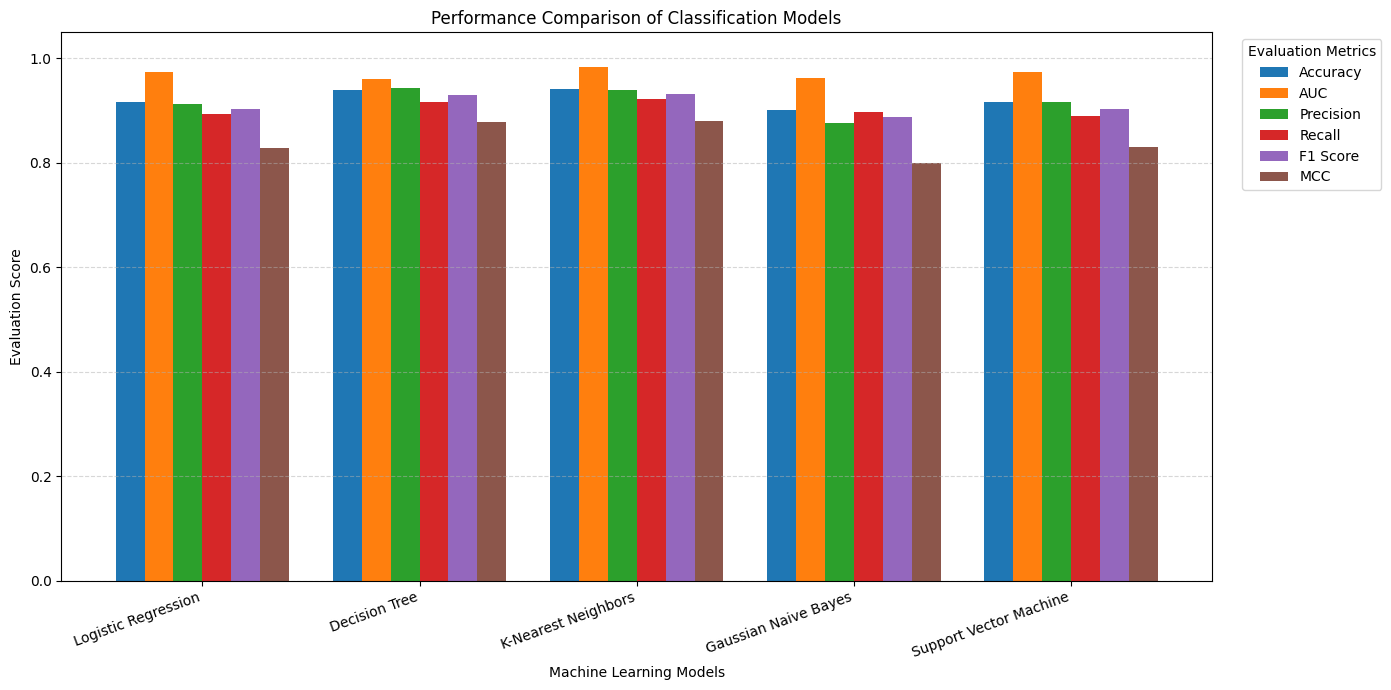

In [27]:
# Plot model performance
ax = final_results_df.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title("Performance Comparison of Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Evaluation Score")

plt.xticks(rotation=20, ha="right")

plt.ylim(0, 1.05)

plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 3.7 Confusion Matrix Analysis

Confusion matrices are generated to examine
the classification errors of each model.

They display True Positive, True Negative,
False Positive, and False Negative predictions.

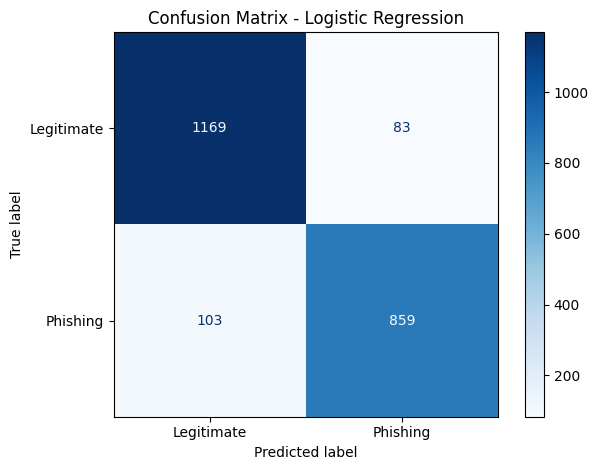

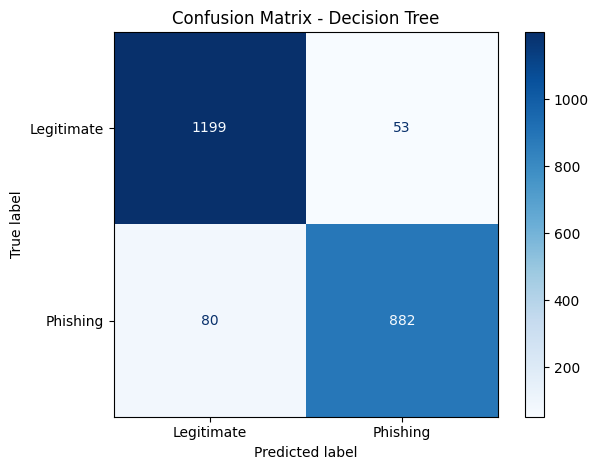

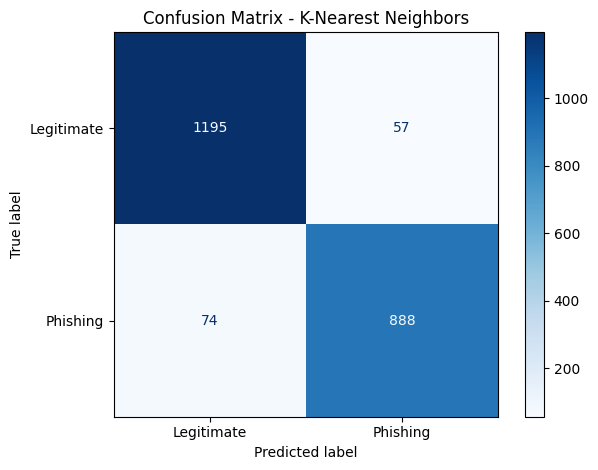

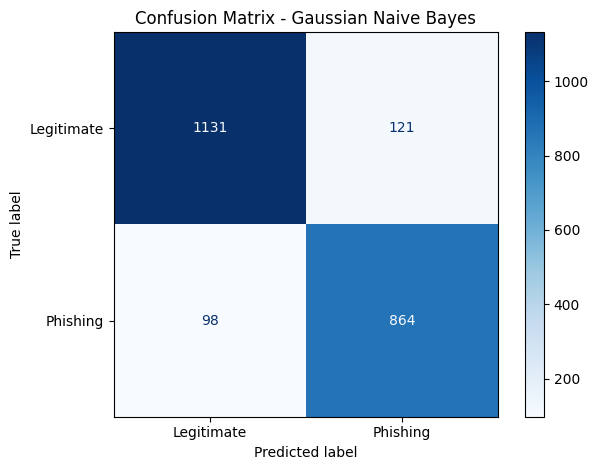

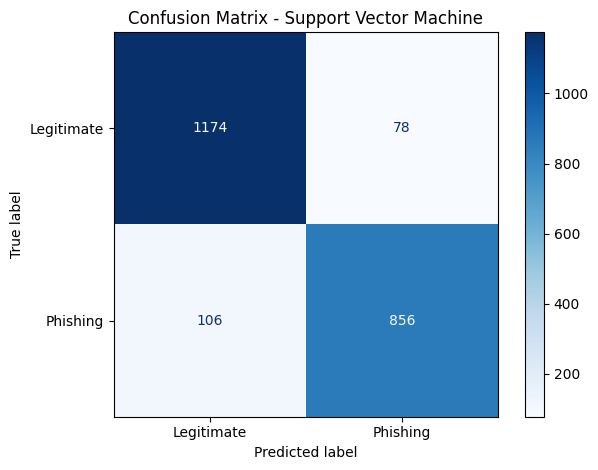

In [28]:
# Generate confusion matrices
for model_name, model in trained_models.items():

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    # Plot confusion matrix
    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Legitimate",
            "Phishing"
        ]
    )

    display_matrix.plot(
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

### 3.8 Classification Reports

Classification reports are generated to examine
Precision, Recall, F1 Score, and Support for
both website classes.

In [29]:
# Generate classification reports
for model_name, model in trained_models.items():

    print("\n" + "=" * 65)
    print("MODEL:", model_name)
    print("=" * 65)

    # Generate predictions
    y_pred = model.predict(X_test)

    # Display classification report
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=[
                "Legitimate",
                "Phishing"
            ],
            zero_division=0
        )
    )


MODEL: Logistic Regression
              precision    recall  f1-score   support

  Legitimate       0.92      0.93      0.93      1252
    Phishing       0.91      0.89      0.90       962

    accuracy                           0.92      2214
   macro avg       0.92      0.91      0.91      2214
weighted avg       0.92      0.92      0.92      2214


MODEL: Decision Tree
              precision    recall  f1-score   support

  Legitimate       0.94      0.96      0.95      1252
    Phishing       0.94      0.92      0.93       962

    accuracy                           0.94      2214
   macro avg       0.94      0.94      0.94      2214
weighted avg       0.94      0.94      0.94      2214


MODEL: K-Nearest Neighbors
              precision    recall  f1-score   support

  Legitimate       0.94      0.95      0.95      1252
    Phishing       0.94      0.92      0.93       962

    accuracy                           0.94      2214
   macro avg       0.94      0.94      0.94      2

### 3.9 Best Model Selection

The models are ranked according to their testing
F1 Scores.

Precision, Recall, AUC, MCC, and generalization
performance are also considered before selecting
the overall best model.

In [30]:
# Rank models by testing F1 Score
model_ranking = final_results_df.sort_values(
    by="F1 Score",
    ascending=False
)

# Display ranking
print("MODEL RANKING")

display(model_ranking.round(4))

# Identify highest F1 model
best_model_name = model_ranking.index[0]

best_model = trained_models[best_model_name]

print("\nBest Model:", best_model_name)

print("\nBest Model Performance:")
display(
    final_results_df.loc[
        best_model_name
    ].to_frame(name="Score").round(4)
)

MODEL RANKING


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
K-Nearest Neighbors,0.9408,0.9833,0.9397,0.9231,0.9313,0.8795
Decision Tree,0.9399,0.9610,0.9433,0.9168,0.9299,0.8776
Support Vector Machine,0.9169,0.9734,0.9165,0.8898,0.9030,0.8306
Logistic Regression,0.9160,0.9738,0.9119,0.8929,0.9023,0.8288
Gaussian Naive Bayes,0.9011,0.9630,0.8772,0.8981,0.8875,0.7994



Best Model: K-Nearest Neighbors

Best Model Performance:


,Score
Accuracy,0.9408
AUC,0.9833
Precision,0.9397
Recall,0.9231
F1 Score,0.9313
MCC,0.8795


# 5. Model Saving and Dataset Exportation

### 5.1 Import Model Saving Libraries

Joblib is used to save the optimized machine learning models for future deployment.

In [31]:
!pip install -q joblib

In [32]:
import os

os.makedirs("model", exist_ok=True)

### 5.2 Save the Trained Models

All five optimized classifiers are saved in `.joblib` format along with their preprocessing pipelines.


In [33]:
import joblib

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "K-Nearest Neighbors": "knn.joblib",
    "Gaussian Naive Bayes": "gaussian_nb.joblib",
    "Support Vector Machine": "svm.joblib"
}

for model_name, filename in model_files.items():
    joblib.dump(
        trained_models[model_name],
        f"model/{filename}"
    )

print("All five models saved successfully!")

All five models saved successfully!


In [34]:
os.listdir("model")

['knn.joblib',
 'decision_tree.joblib',
 'svm.joblib',
 'logistic_regression.joblib',
 'gaussian_nb.joblib']


### 5.3 Export the Test Dataset

The held-out test dataset is exported as a CSV file containing all input features and the target column for application-based evaluation.



In [35]:
test_data = X_test.copy()

test_data["is_phishing"] = y_test

test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved!")
print(test_data.shape)

Test dataset saved!
(2214, 31)


# 6. Streamlit Application and Deployment

## 6.1 Prepare the GitHub Repository

The required application files, saved models, test dataset, dependencies, and source code are organized into a GitHub repository.

In [36]:
!pip install -q PyGithub

In [37]:
from getpass import getpass
from github import Github

token = getpass("Enter your GitHub token: ")

github = Github(token)

user = github.get_user()

print("Connected to GitHub:", user.login)

Enter your GitHub token: ··········


/tmp/ipykernel_5933/2754220026.py:6: DeprecationWarning: Argument login_or_token is deprecated, please use auth=github.Auth.Token(...) instead
  github = Github(token)


Connected to GitHub: Akashshiva


In [38]:
repo = github.get_repo(
    f"{user.login}/Phishing_Website_Detection"
)

print("Connected to repository:", repo.full_name)

Connected to repository: Akashshiva/Phishing_Website_Detection


### 6.2 Develop the Streamlit Application

A Streamlit application is developed to upload test data, select a trained classifier, and display evaluation results.

In [39]:
%%writefile app.py

import os
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)


# ==========================================================
# 1. PAGE CONFIGURATION
# ==========================================================

st.set_page_config(
    page_title="PhishGuard | Security Analytics",
    page_icon="🛡️",
    layout="wide",
    initial_sidebar_state="expanded"
)

BASE_DIR = Path(__file__).resolve().parent


# ==========================================================
# 2. CUSTOM UI / UX DESIGN
# ==========================================================

st.markdown("""
<style>

/* Main application */
.stApp {
    background: linear-gradient(
        135deg,
        #08111F 0%,
        #101B2D 55%,
        #0B1524 100%
    );
}

/* Main content spacing */
.stMainBlockContainer,
div[data-testid="stMainBlockContainer"] {
    max-width: 1500px;
    padding-top: 4.5rem !important;
    padding-bottom: 3rem;
}

/* Sidebar */
section[data-testid="stSidebar"] {
    background-color: #0D1829;
    border-right: 1px solid #24334B;
}

section[data-testid="stSidebar"] h1,
section[data-testid="stSidebar"] h2,
section[data-testid="stSidebar"] h3 {
    color: #E8F0FC;
}

/* Main headings */
h1, h2, h3 {
    color: #F3F7FF !important;
    font-weight: 700 !important;
}

p, label {
    color: #C4D0E0;
}

/* Header */
.hero {
    background: linear-gradient(
        115deg,
        #122D4B,
        #123D59,
        #102D42
    );
    padding: 30px;
    border-radius: 18px;
    border: 1px solid #28506C;
    margin-bottom: 25px;
}

.hero-title {
    color: #FFFFFF;
    font-size: 34px;
    font-weight: 800;
    letter-spacing: -1px;
}

.hero-subtitle {
    color: #B9D2E9;
    font-size: 15px;
    margin-top: 8px;
}

.hero-tag {
    display: inline-block;
    background: #164D51;
    color: #7CE8D0;
    border: 1px solid #267C77;
    border-radius: 20px;
    padding: 5px 12px;
    font-size: 12px;
    margin-top: 15px;
}

/* Metric cards */
div[data-testid="stMetric"] {
    background: linear-gradient(
        145deg,
        #17283E,
        #132238
    );
    border: 1px solid #2A405D;
    border-radius: 14px;
    padding: 19px;
    min-height: 115px;
    box-shadow: 0 4px 15px rgba(0,0,0,0.15);
}

div[data-testid="stMetricLabel"] {
    color: #AFC2D8;
    font-size: 13px;
}

div[data-testid="stMetricValue"] {
    color: #FFFFFF;
    font-size: 26px;
    font-weight: 750;
}

/* Tabs */
button[data-baseweb="tab"] {
    font-size: 14px;
    font-weight: 600;
    color: #AFC2D8;
}

/* Dataframes */
div[data-testid="stDataFrame"] {
    border: 1px solid #2A405D;
    border-radius: 12px;
}

/* Buttons */
.stButton > button {
    border-radius: 10px;
    border: 1px solid #2788BA;
    background: #14577C;
    color: white;
    font-weight: 650;
}

.stButton > button:hover {
    background: #1976A5;
    border-color: #54BCEB;
    color: white;
}

/* Download button */
.stDownloadButton > button {
    border-radius: 10px;
    background: #087D70;
    color: white;
    border: 1px solid #23B7A4;
    font-weight: 650;
}

/* Section cards */
.panel {
    background: #142238;
    border: 1px solid #293E59;
    border-radius: 14px;
    padding: 18px;
    margin-bottom: 15px;
}

.panel-title {
    color: #EAF3FF;
    font-size: 17px;
    font-weight: 700;
    margin-bottom: 8px;
}

/* Small captions */
.muted {
    color: #91A8C3;
    font-size: 13px;
}

/* Status */
.success-text {
    color: #61DDB8;
    font-weight: 650;
}

.warning-text {
    color: #F5C16C;
    font-weight: 650;
}

/* Dividers */
hr {
    border-color: #2B405B;
}

</style>
""", unsafe_allow_html=True)


# ==========================================================
# 3. APPLICATION HEADER
# ==========================================================

st.html("""
<div style="
    background: linear-gradient(115deg, #122D4B, #123D59, #102D42);
    padding: 32px;
    border-radius: 18px;
    border: 1px solid #28506C;
    margin-bottom: 25px;
">

    <div style="
        color: #FFFFFF;
        font-size: 38px;
        font-weight: 800;
        letter-spacing: -1px;
    ">
        🛡️ PhishGuard
    </div>

    <div style="
        color: #B9D2E9;
        font-size: 16px;
        margin-top: 10px;
    ">
        Intelligent Phishing Website Detection
        &nbsp; | &nbsp;
        Machine Learning Security Analytics
    </div>

    <div style="
        display: inline-block;
        background: #164D51;
        color: #7CE8D0;
        border: 1px solid #267C77;
        border-radius: 20px;
        padding: 6px 14px;
        font-size: 12px;
        margin-top: 18px;
    ">
        ● SECURITY ANALYTICS DASHBOARD
    </div>

</div>
""")


# ==========================================================
# 4. MODEL CONFIGURATION
# ==========================================================

MODEL_FILES = {
    "Logistic Regression": "model/logistic_regression.joblib",
    "Decision Tree": "model/decision_tree.joblib",
    "K-Nearest Neighbors": "model/knn.joblib",
    "Gaussian Naive Bayes": "model/gaussian_nb.joblib",
    "Support Vector Machine": "model/svm.joblib"
}

MODEL_DESCRIPTIONS = {
    "Logistic Regression":
        "Linear classification using probability estimation.",

    "Decision Tree":
        "Tree-based classification using feature conditions.",

    "K-Nearest Neighbors":
        "Distance-based classification using nearest observations.",

    "Gaussian Naive Bayes":
        "Probabilistic classification based on Gaussian assumptions.",

    "Support Vector Machine":
        "Linear classification using an optimal decision boundary."
}


# ==========================================================
# 5. LOAD SAVED MODELS
# ==========================================================

@st.cache_resource(show_spinner=False)
def load_model(model_path):

    path = BASE_DIR / model_path

    if not path.exists():
        raise FileNotFoundError(
            f"Model file not found: {model_path}"
        )

    return joblib.load(path)


# ==========================================================
# 6. MODEL EVALUATION FUNCTION
# ==========================================================

def evaluate_model(model, test_data):

    target_column = "is_phishing"

    # Separate input features and target
    X_test = test_data.drop(columns=[target_column])

    y_test = pd.to_numeric(
        test_data[target_column],
        errors="coerce"
    )

    # Validate target
    if y_test.isna().any():
        raise ValueError("Invalid target values detected.")

    if not set(y_test.unique()).issubset({0, 1}):
        raise ValueError(
            "Target labels must be 0 or 1."
        )

    if y_test.nunique() != 2:
        raise ValueError(
            "Both legitimate and phishing classes are required."
        )

    # Retrieve expected feature names
    expected_features = list(model.feature_names_in_)

    # Check missing features
    missing_features = [
        col for col in expected_features
        if col not in X_test.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing required features: {missing_features}"
        )

    # Identify extra columns
    extra_features = [
        col for col in X_test.columns
        if col not in expected_features
    ]

    # Preserve training feature order
    X_test = X_test[expected_features].copy()

    # Validate numeric features
    numeric_data = X_test.apply(
        pd.to_numeric,
        errors="coerce"
    )

    invalid_values = numeric_data.isna() & X_test.notna()

    if invalid_values.any().any():
        raise ValueError(
            "Non-numeric feature values detected."
        )

    X_test = numeric_data.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate continuous scores for AUC
    if hasattr(model, "predict_proba"):

        model_classes = list(model.classes_)

        positive_index = model_classes.index(1)

        y_score = model.predict_proba(X_test)[
            :, positive_index
        ]

    elif hasattr(model, "decision_function"):

        y_score = model.decision_function(X_test)

        if list(model.classes_)[1] != 1:
            y_score = -y_score

    else:
        raise ValueError(
            "Model does not support AUC calculation."
        )

    # Calculate evaluation metrics
    metrics = {

        "Accuracy": accuracy_score(
            y_test,
            y_pred
        ),

        "AUC": roc_auc_score(
            y_test,
            y_score
        ),

        "Precision": precision_score(
            y_test,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "MCC": matthews_corrcoef(
            y_test,
            y_pred
        )
    }

    # Classification report
    report = classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Legitimate",
            "Phishing"
        ],
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).T

    # Confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    # Prepare prediction results
    predictions = test_data.copy()

    predictions["predicted_class"] = y_pred

    predictions["predicted_label"] = np.where(
        y_pred == 1,
        "Phishing",
        "Legitimate"
    )

    predictions["prediction_result"] = np.where(
        y_pred == y_test.to_numpy(),
        "Correct",
        "Incorrect"
    )

    return {
        "metrics": metrics,
        "report": report_df,
        "confusion_matrix": cm,
        "predictions": predictions,
        "extra_features": extra_features
    }


# ==========================================================
# 7. SIDEBAR CONTROLS
# ==========================================================

st.sidebar.markdown("## ⚙️ Control Center")

# Evaluation mode
st.sidebar.markdown("### Evaluation Mode")

view_mode = st.sidebar.radio(
    "Choose evaluation mode",
    [
        "Single Model",
        "Compare All Models"
    ],
    help="Compare all five saved classifiers or evaluate one model."
)

# Model selection
st.sidebar.markdown("### Model Selection")

selected_model = st.sidebar.selectbox(
    "Choose classifier",
    list(MODEL_FILES.keys())
)

st.sidebar.caption(
    MODEL_DESCRIPTIONS[selected_model]
)

st.sidebar.divider()

# Dataset upload
st.sidebar.markdown("### 📁 Dataset Upload")

uploaded_file = st.sidebar.file_uploader(
    "Upload test dataset",
    type=["csv"],
    help="Upload CSV file"
)

st.sidebar.divider()

st.sidebar.markdown("### About PhishGuard")

st.sidebar.caption(
    "A machine learning application developed "
    "for phishing website classification."
)

st.sidebar.caption(
    "BITS Pilani | M.Tech AIML"
)


# ==========================================================
# 8. WELCOME SCREEN
# ==========================================================

if uploaded_file is None:

    st.markdown("## Welcome to PhishGuard")

    st.markdown(
        "Analyze phishing detection models using "
        "your prepared test dataset."
    )

    st.info(
        "Upload your test CSV from the sidebar "
        "to start the evaluation."
    )

    st.markdown("### Dashboard Capabilities")

    col1, col2, col3 = st.columns(3)

    with col1:
        st.markdown("""
        <div class="panel">
            <div class="panel-title">📁 Dataset Analysis</div>
            <div class="muted">
                Upload your test dataset and inspect
                its features and class distribution.
            </div>
        </div>
        """, unsafe_allow_html=True)

    with col2:
        st.markdown("""
        <div class="panel">
            <div class="panel-title">🤖 Model Evaluation</div>
            <div class="muted">
                Evaluate five trained machine learning
                classification models.
            </div>
        </div>
        """, unsafe_allow_html=True)

    with col3:
        st.markdown("""
        <div class="panel">
            <div class="panel-title">📊 Performance Analytics</div>
            <div class="muted">
                Explore performance metrics, confusion
                matrices and classification reports.
            </div>
        </div>
        """, unsafe_allow_html=True)

    st.markdown("### Supported Classification Models")

    model_col1, model_col2 = st.columns(2)

    with model_col1:
        for name in list(MODEL_FILES.keys())[:3]:
            st.markdown(f"🔹 {name}")

    with model_col2:
        for name in list(MODEL_FILES.keys())[3:]:
            st.markdown(f"🔹 {name}")

    st.divider()

    st.caption(
        "PhishGuard | Machine Learning Security Analytics"
    )

    st.stop()


# ==========================================================
# 9. READ AND VALIDATE UPLOADED DATASET
# ==========================================================

try:

    test_data = pd.read_csv(uploaded_file)

except Exception as error:

    st.error(f"Unable to read uploaded CSV: {error}")
    st.stop()


if test_data.empty:

    st.error("The uploaded dataset is empty.")
    st.stop()


if "is_phishing" not in test_data.columns:

    st.error(
        "The required target column 'is_phishing' is missing."
    )
    st.stop()


# Validate target
target_values = pd.to_numeric(
    test_data["is_phishing"],
    errors="coerce"
)

if target_values.isna().any():

    st.error("Invalid values found in the target column.")
    st.stop()

if not set(target_values.unique()).issubset({0, 1}):

    st.error("Target labels must be either 0 or 1.")
    st.stop()

if target_values.nunique() != 2:

    st.error(
        "The test dataset must contain both classes "
        "to calculate AUC."
    )
    st.stop()

test_data["is_phishing"] = target_values.astype(int)


# ==========================================================
# 10. DATASET OVERVIEW
# ==========================================================

st.markdown("## 📁 Dataset Overview")

total_records = len(test_data)

total_features = len(test_data.columns) - 1

phishing_count = int(
    (test_data["is_phishing"] == 1).sum()
)

legitimate_count = int(
    (test_data["is_phishing"] == 0).sum()
)

c1, c2, c3, c4 = st.columns(4)

c1.metric(
    "Total Records",
    f"{total_records:,}"
)

c2.metric(
    "Input Features",
    total_features
)

c3.metric(
    "Phishing Records",
    f"{phishing_count:,}"
)

c4.metric(
    "Legitimate Records",
    f"{legitimate_count:,}"
)

st.caption(
    f"File: {uploaded_file.name}  |  "
    f"Size: {uploaded_file.size / 1024:.2f} KB"
)

with st.expander("🔍 Preview Dataset"):

    st.dataframe(
        test_data.head(10),
        use_container_width=True
    )

    st.caption(
        f"Dataset dimensions: {test_data.shape}"
    )


# ==========================================================
# 11. MODEL EVALUATION
# ==========================================================

if view_mode == "Single Model":

    models_to_evaluate = [selected_model]

else:

    models_to_evaluate = list(MODEL_FILES.keys())


all_results = {}
failed_models = {}

with st.spinner(
    "Analyzing dataset and evaluating saved models..."
):

    for model_name in models_to_evaluate:

        try:

            model = load_model(
                MODEL_FILES[model_name]
            )

            all_results[model_name] = evaluate_model(
                model,
                test_data
            )

        except Exception as error:

            failed_models[model_name] = str(error)


if failed_models:

    st.error("Some models could not be evaluated.")

    for name, error in failed_models.items():
        st.write(f"**{name}:** {error}")

    if not all_results:
        st.stop()


# Determine detailed model
detail_model = (
    selected_model
    if selected_model in all_results
    else next(iter(all_results))
)

selected_result = all_results[detail_model]


# ==========================================================
# 12. DASHBOARD NAVIGATION
# ==========================================================

tab_overview, tab_compare, tab_confusion, tab_report, tab_predictions = st.tabs(
    [
        "📊 Overview",
        "📈 Model Comparison",
        "🎯 Confusion Matrix",
        "📋 Classification Report",
        "📥 Predictions"
    ]
)


# ==========================================================
# 13. OVERVIEW
# ==========================================================

with tab_overview:

    st.markdown("### Model Performance Overview")

    st.markdown(
        f"Detailed evaluation for **{detail_model}**"
    )

    metrics = selected_result["metrics"]

    # Row 1
    m1, m2, m3 = st.columns(3)

    m1.metric(
        "Accuracy",
        f"{metrics['Accuracy']:.2%}"
    )

    m2.metric(
        "ROC AUC",
        f"{metrics['AUC']:.2%}"
    )

    m3.metric(
        "Precision",
        f"{metrics['Precision']:.2%}"
    )

    # Row 2
    m4, m5, m6 = st.columns(3)

    m4.metric(
        "Recall",
        f"{metrics['Recall']:.2%}"
    )

    m5.metric(
        "F1 Score",
        f"{metrics['F1 Score']:.2%}"
    )

    m6.metric(
        "MCC",
        f"{metrics['MCC']:.4f}"
    )

    st.divider()

    st.markdown("### Prediction Summary")

    predictions = selected_result["predictions"]

    correct = int(
        (predictions["prediction_result"] == "Correct").sum()
    )

    incorrect = total_records - correct

    p1, p2, p3 = st.columns(3)

    p1.metric(
        "Correct Predictions",
        f"{correct:,}"
    )

    p2.metric(
        "Incorrect Predictions",
        f"{incorrect:,}"
    )

    p3.metric(
        "Prediction Accuracy",
        f"{correct / total_records:.2%}"
    )

    st.markdown("### Dataset Class Distribution")

    class_data = pd.DataFrame({
        "Website Type": [
            "Legitimate",
            "Phishing"
        ],
        "Records": [
            legitimate_count,
            phishing_count
        ]
    })

    st.bar_chart(
        class_data.set_index("Website Type"),
        color="#3B82F6"
    )


# ==========================================================
# 14. MODEL COMPARISON
# ==========================================================

with tab_compare:

    st.markdown("### Comparative Model Performance")

    if len(all_results) < 2:

        st.info(
            "Select 'Compare All Models' from the sidebar "
            "to view all five classifiers together."
        )

    else:

        comparison_df = pd.DataFrame({
            name: result["metrics"]
            for name, result in all_results.items()
        }).T

        st.dataframe(
            comparison_df.style.format(
                "{:.4f}"
            ).highlight_max(
                axis=0,
                color="#145C50"
            ),
            use_container_width=True
        )

        st.markdown("### Performance Visualization")

        selected_metrics = st.multiselect(
            "Choose metrics",
            list(comparison_df.columns),
            default=[
                "Accuracy",
                "AUC",
                "Precision",
                "Recall",
                "F1 Score"
            ]
        )

        if selected_metrics:
          # Define chart colors for different metrics
          chart_colors = [
              "#20BFA8",
              "#3B82F6",
              "#A78BFA",
              "#F59E0B",
              "#F472B6",
              "#22D3EE"
          ]

          # Display interactive comparison chart
          st.bar_chart(
              comparison_df,
              y=selected_metrics,
              color=chart_colors[:len(selected_metrics)],
              horizontal=True,
              stack=False,
              sort=False,
              height=550,
              width="stretch",
              x_label=" ",
              y_label="Model Performance Score"
          )

        st.markdown("### Model Ranking")

        ranking = comparison_df.sort_values(
            by="F1 Score",
            ascending=False
        )

        ranking_display = ranking[
            ["Accuracy", "AUC", "F1 Score", "MCC"]
        ]

        st.dataframe(
            ranking_display.style.format("{:.4f}"),
            use_container_width=True
        )

        best_name = ranking.index[0]

        st.success(
            f"🏆 Highest Testing F1 Score: {best_name}"
        )


# ==========================================================
# 15. CONFUSION MATRIX
# ==========================================================

with tab_confusion:

    st.markdown("### Confusion Matrix")

    st.caption(
        f"Selected model: {detail_model}"
    )

    cm = selected_result["confusion_matrix"]

    fig, ax = plt.subplots(figsize=(7, 5))

    fig.patch.set_facecolor("#142238")
    ax.set_facecolor("#142238")

    image = ax.imshow(
        cm,
        cmap="GnBu"
    )

    ax.set_xticks(
        [0, 1],
        labels=["Legitimate", "Phishing"]
    )

    ax.set_yticks(
        [0, 1],
        labels=["Legitimate", "Phishing"]
    )

    ax.set_xlabel(
        "Predicted Class",
        color="white"
    )

    ax.set_ylabel(
        "Actual Class",
        color="white"
    )

    ax.tick_params(colors="white")

    ax.set_title(
        "Classification Outcomes",
        color="white",
        pad=15
    )

    threshold = cm.max() / 2

    for i in range(2):

        for j in range(2):

            ax.text(
                j,
                i,
                f"{cm[i, j]:,}",
                ha="center",
                va="center",
                fontsize=16,
                fontweight="bold",
                color=(
                    "white"
                    if cm[i, j] > threshold
                    else "#102438"
                )
            )

    colorbar = fig.colorbar(
        image,
        ax=ax
    )

    colorbar.ax.yaxis.set_tick_params(
        color="white"
    )

    plt.tight_layout()

    st.pyplot(
        fig,
        use_container_width=False
    )

    plt.close(fig)

    tn, fp, fn, tp = cm.ravel()

    st.markdown("### Classification Outcomes")

    a, b = st.columns(2)

    a.metric("True Negatives", f"{tn:,}")
    b.metric("False Positives", f"{fp:,}")

    c, d = st.columns(2)

    c.metric("False Negatives", f"{fn:,}")
    d.metric("True Positives", f"{tp:,}")


# ==========================================================
# 16. CLASSIFICATION REPORT
# ==========================================================

with tab_report:

    st.markdown("### Detailed Classification Report")

    report_df = selected_result["report"].copy()

    st.dataframe(
        report_df.style.format({
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1-score": "{:.4f}",
            "support": "{:.0f}"
        }),
        use_container_width=True
    )

    st.caption(
        "The report includes precision, recall, F1 Score "
        "and support for both website classes."
    )


# ==========================================================
# 17. PREDICTION RESULTS
# ==========================================================

with tab_predictions:

    st.markdown("### Website Classification Results")

    prediction_df = selected_result["predictions"]

    filter_option = st.selectbox(
        "Filter predictions",
        [
            "All Records",
            "Correct Predictions",
            "Incorrect Predictions",
            "Predicted Phishing",
            "Predicted Legitimate"
        ]
    )

    if filter_option == "Correct Predictions":

        display_df = prediction_df[
            prediction_df["prediction_result"] == "Correct"
        ]

    elif filter_option == "Incorrect Predictions":

        display_df = prediction_df[
            prediction_df["prediction_result"] == "Incorrect"
        ]

    elif filter_option == "Predicted Phishing":

        display_df = prediction_df[
            prediction_df["predicted_class"] == 1
        ]

    elif filter_option == "Predicted Legitimate":

        display_df = prediction_df[
            prediction_df["predicted_class"] == 0
        ]

    else:

        display_df = prediction_df

    st.caption(
        f"Displaying {len(display_df):,} of {total_records:,} records."
    )

    st.dataframe(
        display_df,
        use_container_width=True,
        height=450
    )

    st.markdown("### Export Results")

    csv_data = prediction_df.to_csv(
        index=False
    ).encode("utf-8")

    st.download_button(
        label="⬇️ Download Prediction Results",
        data=csv_data,
        file_name="phishing_predictions.csv",
        mime="text/csv",
        type="primary"
    )


# ==========================================================
# 18. FOOTER
# ==========================================================

st.divider()

footer_left, footer_right = st.columns(2)

with footer_left:

    st.markdown(
        "**🛡️ PhishGuard**  \n"
        "Intelligent Phishing Website Detection"
    )

with footer_right:

    st.markdown(
        "<div style='text-align:right;color:#91A8C3;'>"
        "BITS Pilani | M.Tech AIML<br>"
        "Machine Learning Classification Project"
        "</div>",
        unsafe_allow_html=True
    )

st.caption(
    "Evaluation is performed using saved models. "
    "No model retraining is performed on uploaded test data."
)

Writing app.py


### 6.3 Implement Model Evaluation

The application loads the saved model and evaluates the uploaded test dataset without retraining.


In [40]:
%%writefile requirements.txt

streamlit
scikit-learn==1.6.1
numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
joblib==1.6.0
threadpoolctl==3.7.0
matplotlib==3.10.0

Writing requirements.txt


In [41]:
%%writefile .gitignore

__pycache__/
*.pyc
.ipynb_checkpoints/
.env

Writing .gitignore


In [42]:
import os

print(os.listdir("."))
print(os.listdir("model"))

['.config', '.gitignore', 'model', 'requirements.txt', 'test_data.csv', 'hyperparameter_tuning_results.csv', 'app.py', 'sample_data']
['knn.joblib', 'decision_tree.joblib', 'svm.joblib', 'logistic_regression.joblib', 'gaussian_nb.joblib']


In [43]:
from github import Github, Auth
from getpass import getpass
import os

# GitHub authentication
token = getpass("GitHub token: ")

auth = Auth.Token(token)
github = Github(auth=auth)

# Get authenticated user
user = github.get_user()

print("Connected to GitHub:", user.login)

# Connect to repository
repo = github.get_repo(
    f"{user.login}/Phishing_Website_Detection"
)

print("Repository:", repo.full_name)


# Upload or update files
def upload_file(local_path, github_path):

    if not os.path.exists(local_path):
        print("Local file not found:", local_path)
        return

    with open(local_path, "rb") as file:
        content = file.read()

    try:
        existing_file = repo.get_contents(github_path)

        repo.update_file(
            path=github_path,
            message=f"Update {github_path}",
            content=content,
            sha=existing_file.sha
        )

        print("Updated:", github_path)

    except Exception as error:

        # Only create if the file does not already exist
        if getattr(error, "status", None) == 404:

            repo.create_file(
                path=github_path,
                message=f"Add {github_path}",
                content=content
            )

            print("Uploaded:", github_path)

        else:
            print("GitHub API Error:", error)

GitHub token: ··········
Connected to GitHub: Akashshiva
Repository: Akashshiva/Phishing_Website_Detection


In [44]:
upload_file("app.py", "app.py")
upload_file("requirements.txt", "requirements.txt")
upload_file("test_data.csv", "test_data.csv")

Updated: app.py
Updated: requirements.txt
Updated: test_data.csv


In [45]:
for filename in os.listdir("model"):

    local_path = f"model/{filename}"
    github_path = f"model/{filename}"

    upload_file(local_path, github_path)

Updated: model/knn.joblib
Updated: model/decision_tree.joblib
Updated: model/svm.joblib
Updated: model/logistic_regression.joblib
Updated: model/gaussian_nb.joblib
